# Module 07 — Exercises — Solutions

These exercises follow the order of the concept guide: counting and the axioms, conditional probability
and Bayes' theorem, random variables, expectation and variance, Monte Carlo, and finally naive Bayes.
Several checks compare your answer against a *hidden* value, so compute carefully rather than guessing.

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb, factorial
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — Compound events by counting  `★☆☆`

Two fair dice are rolled; a 52-card deck is shuffled. Using only counting (enumerate the 36 outcomes of
the dice as pairs; use `comb` for the cards), assign these five **floats**:

* `p_sum_ge_10` — the sum of the two dice is at least 10;
* `p_diff_1` — the two faces differ by exactly 1;
* `p_sum_ge_10_or_diff_1` — the union of the two events above (check your answer against inclusion–exclusion);
* `p_two_aces` — a two-card hand consists of two aces;
* `p_at_least_one_ace_5cards` — a five-card hand contains at least one ace (hint: complement).

In [3]:
from itertools import product
omega = [(i, j) for i, j in product(range(1, 7), repeat=2)]

def p_event(predicate):
    return sum(1 for w in omega if predicate(w)) / len(omega)

p_sum_ge_10 = p_event(lambda w: sum(w) >= 10)
p_diff_1 = p_event(lambda w: abs(w[0] - w[1]) == 1)
p_sum_ge_10_or_diff_1 = p_event(lambda w: sum(w) >= 10 or abs(w[0] - w[1]) == 1)
p_two_aces = comb(4, 2) / comb(52, 2)
p_at_least_one_ace_5cards = 1 - comb(48, 5) / comb(52, 5)

**Check your answer:**

In [4]:
check_close('P(sum >= 10) = 6/36', p_sum_ge_10, 6/36)
check_hash('P(|difference| = 1)', p_diff_1, '13295ac05dd1407f')
check_hash('P(sum >= 10 or |difference| = 1)', p_sum_ge_10_or_diff_1, '2f4846657699299d')
try:
    ie = p_sum_ge_10 + p_diff_1 - p_sum_ge_10_or_diff_1
except Exception:
    ie = None
check_hash('the intersection implied by inclusion-exclusion', ie, '69fe3b6da23be33d')
check_close('P(two aces) = 1/221', p_two_aces, 1/221)
check_hash('P(at least one ace in 5 cards)', p_at_least_one_ace_5cards, '8fcc859a5186dffe')

✅ P(sum >= 10) = 6/36
✅ P(|difference| = 1)
✅ P(sum >= 10 or |difference| = 1)
✅ the intersection implied by inclusion-exclusion
✅ P(two aces) = 1/221
✅ P(at least one ace in 5 cards)


True

**Why this works**

With equally likely outcomes, probability is a ratio of counts. "Sum $\ge 10$" has 6 outcomes
$\{(4,6),(5,5),(6,4),(5,6),(6,5),(6,6)\}$; "differ by 1" has 10; they share $(5,6)$ and $(6,5)$, so the
union has $6 + 10 - 2 = 14$ outcomes — inclusion–exclusion in action. For the cards,
$\binom{4}{2}/\binom{52}{2} = 6/1326 = 1/221$, and "at least one ace" is easiest through its complement
"no ace": $1 - \binom{48}{5}/\binom{52}{5} \approx 0.341$. The common wrong turn is to compute
$P(\text{at least one ace}) = 5 \times 4/52$, which double-counts hands with several aces (that is the union
bound, an overestimate).

## Exercise 2 — Law of total probability: three suppliers  `★☆☆`

A factory buys the same component from three suppliers, who deliver shares $P(S_1), P(S_2), P(S_3)$ of
the stock with defect rates $P(D \mid S_i)$. Implement

* `p_defective(shares, defect_rates)` → the overall defect probability $P(D) = \sum_i P(D \mid S_i)P(S_i)$ as a float;
* `p_supplier_given_defective(shares, defect_rates)` → a NumPy array with $P(S_i \mid D)$ for each supplier (Bayes' theorem, one entry per supplier, summing to 1).

Both take Python lists or arrays of equal length. Test case: shares `[0.5, 0.3, 0.2]`, defect rates
`[0.01, 0.02, 0.05]`.

In [5]:
def p_defective(shares, defect_rates):
    shares = np.asarray(shares, dtype=float); defect_rates = np.asarray(defect_rates, dtype=float)
    return float(shares @ defect_rates)

def p_supplier_given_defective(shares, defect_rates):
    shares = np.asarray(shares, dtype=float); defect_rates = np.asarray(defect_rates, dtype=float)
    joint = shares * defect_rates
    return joint / joint.sum()

**Check your answer:**

In [6]:
try:
    got = p_defective([0.5, 0.3, 0.2], [0.01, 0.02, 0.05])
except Exception:
    got = None
check_hash('P(defective) for the three suppliers', got, '089bbc1623e20a9c', decimals=4)
try:
    got_single = p_defective([1.0], [0.07])
except Exception:
    got_single = None
check_close('single supplier: P(D) = its defect rate', got_single, 0.07)
try:
    post = np.asarray(p_supplier_given_defective([0.5, 0.3, 0.2], [0.01, 0.02, 0.05]), dtype=float)
    ok_shape = post.shape == (3,)
except Exception:
    post, ok_shape = None, False
check('posterior has shape (3,)', ok_shape)
check_hash('P(S_3 | defective)', (float(post[2]) if ok_shape else None), '454cbd3d7aa16f21')
check_close('posterior sums to 1', (float(post.sum()) if ok_shape else None), 1.0)

✅ P(defective) for the three suppliers
✅ single supplier: P(D) = its defect rate
✅ posterior has shape (3,)
✅ P(S_3 | defective)
✅ posterior sums to 1


True

**Why this works**

The suppliers partition the stock, so $P(D) = 0.5 \cdot 0.01 + 0.3 \cdot 0.02 + 0.2 \cdot 0.05 = 0.021$.
Bayes' theorem then divides each joint probability $P(D \mid S_i)P(S_i)$ by that total: supplier 3 delivers
only 20% of the parts but $0.010/0.021 \approx 48\%$ of the defects. A dot product does the whole law of
total probability in one line; normalising the vector of joints gives all three posteriors at once — the
pattern `joint / joint.sum()` is Bayes' theorem for any finite set of hypotheses.

## Exercise 3 — Independent or mutually exclusive?  `★☆☆`

A colleague argues: "Our two fraud rules never fire on the same transaction — rule A catches card-not-present
fraud, rule B catches account takeovers. Since they never overlap, the two alerts are independent, so I can
multiply their probabilities to get the chance that a transaction triggers both."

1. Identify the error. Are events that never overlap independent? Prove your answer with the definition
   $P(A \cap B) = P(A)P(B)$, assuming $P(A) = 0.02$ and $P(B) = 0.01$.
2. What is $P(A \mid B)$ for mutually exclusive events with positive probability, and what does that say
   about dependence?
3. Give one example of two events that *are* independent and one of two that are mutually exclusive, both
   from the same experiment (e.g. two dice), and compute the relevant probabilities.

**Answer**

1. Mutually exclusive means $A \cap B = \emptyset$, so $P(A \cap B) = 0$. Independence would require
   $P(A \cap B) = P(A)P(B) = 0.02 \times 0.01 = 0.0002 \ne 0$. The two notions are incompatible whenever both
   probabilities are positive: the colleague's "multiply the probabilities" gives $0.0002$ for an event that
   has probability exactly $0$.
2. $P(A \mid B) = P(A \cap B)/P(B) = 0$, whereas $P(A) = 0.02$. Learning that $B$ occurred changes the
   probability of $A$ (to zero), which is the definition of *dependence* — mutually exclusive events are as
   dependent as events can be.
3. Two dice: "first die shows 6" and "second die shows 6" are independent, $P = \frac{1}{6}\cdot\frac{1}{6} = \frac{1}{36}$,
   and indeed exactly one of the 36 outcomes is $(6, 6)$. "Sum is 7" and "doubles" are mutually exclusive
   (7 is odd), so $P(\text{both}) = 0$ while $P(\text{sum } 7)\,P(\text{doubles}) = \frac{1}{6}\cdot\frac{1}{6} \ne 0$,
   and $P(\text{sum } 7 \cup \text{doubles}) = \frac{6}{36} + \frac{6}{36} = \frac{1}{3}$ by additivity.

## Exercise 4 — Bayes' theorem: PPV, the break-even prevalence and a second test  `★★☆`

Implement three functions (all arguments and results are floats):

* `ppv(sensitivity, specificity, prevalence)` — $P(D \mid +)$;
* `prevalence_for_ppv(sensitivity, specificity, target=0.5)` — the prevalence at which the PPV equals `target` (solve the PPV formula for the prevalence; for `target=0.5` the answer is $\frac{1 - \text{sp}}{\text{se} + 1 - \text{sp}}$);
* `ppv_after_two_positives(sensitivity, specificity, prevalence)` — the posterior probability of disease after **two** positive results from conditionally independent tests (use the odds form: multiply the prior odds by the likelihood ratio twice).

Test case: a screening test with sensitivity 0.90 and specificity 0.97 for a condition with prevalence 0.2%.

In [7]:
def ppv(sensitivity, specificity, prevalence):
    tp = sensitivity * prevalence
    fp = (1 - specificity) * (1 - prevalence)
    return tp / (tp + fp)

def prevalence_for_ppv(sensitivity, specificity, target=0.5):
    # solve se*pi / (se*pi + (1-sp)(1-pi)) = target for pi
    fpr = 1 - specificity
    return target * fpr / (sensitivity * (1 - target) + target * fpr)

def ppv_after_two_positives(sensitivity, specificity, prevalence):
    prior_odds = prevalence / (1 - prevalence)
    lr = sensitivity / (1 - specificity)
    post_odds = prior_odds * lr * lr
    return post_odds / (1 + post_odds)

**Check your answer:**

In [8]:
try:
    got = ppv(0.99, 0.95, 0.01)
except Exception:
    got = None
check_close('the guide example: PPV = 1/6', got, 1/6, tol=1e-6)
try:
    got = ppv(0.90, 0.97, 0.002)
except Exception:
    got = None
check_hash('PPV for se 0.90, sp 0.97, prevalence 0.002', got, 'ce455c7dc1cb7521', decimals=4)
try:
    got = prevalence_for_ppv(0.90, 0.97, 0.5)
except Exception:
    got = None
check_hash('prevalence at which PPV = 50%', got, '5201add9d71b6f7a', decimals=4)
try:
    got = ppv(0.90, 0.97, prevalence_for_ppv(0.90, 0.97, 0.5))
except Exception:
    got = None
check_close('consistency: ppv at that prevalence is 0.5', got, 0.5)
try:
    got = prevalence_for_ppv(0.85, 0.93, 0.9)
except Exception:
    got = None
check_hash('prevalence needed for PPV = 90% with se 0.85, sp 0.93', got, '1df868e4e88c5d91', decimals=4)
try:
    got = ppv_after_two_positives(0.90, 0.97, 0.002)
except Exception:
    got = None
check_hash('posterior after two positive tests', got, '2150b8d54470980c', decimals=4)

✅ the guide example: PPV = 1/6
✅ PPV for se 0.90, sp 0.97, prevalence 0.002
✅ prevalence at which PPV = 50%
✅ consistency: ppv at that prevalence is 0.5
✅ prevalence needed for PPV = 90% with se 0.85, sp 0.93
✅ posterior after two positive tests


True

**Why this works**

PPV is Bayes' theorem with the evidence expanded by total probability. Setting it equal to a target $t$ and
solving gives $\pi = \frac{t(1 - \text{sp})}{\text{se}(1 - t) + t(1 - \text{sp})}$, which reduces to
$\frac{1 - \text{sp}}{\text{se} + 1 - \text{sp}}$ at $t = 0.5$. For the second test the odds form is
cleanest: prior odds $0.002/0.998$, likelihood ratio $0.90/0.03 = 30$, so two positives multiply the odds
by 900 and take the posterior from about 5.7% to about 64%. The usual mistake is to feed the first
posterior back into `ppv` as the new prevalence — which is correct and gives the same number — but to then
*also* forget that this assumes the two test results are conditionally independent given the disease
status.

## Exercise 5 — The birthday problem, exactly and by simulation  `★★☆`

Implement

* `birthday_exact(n, days=365)` — the exact probability that among $n$ people at least two share a birthday, via the product $1 - \prod_{i=0}^{n-1}\frac{\text{days}-i}{\text{days}}$;
* `birthday_simulated(n, n_trials, rng, days=365)` — a Monte Carlo estimate from `n_trials` random groups, drawing birthdays with `rng.integers(0, days, size=(n_trials, n))` (vectorised: sort each row and look for equal neighbours, or use any other correct method);
* `smallest_group_for(threshold, days=365)` — the smallest $n$ with `birthday_exact(n) >= threshold`.

Then compare: for $n = 23$ and 20,000 trials, how far is the simulation from the exact value relative to
the standard error $\sqrt{p(1-p)/20{,}000}$?

In [9]:
def birthday_exact(n, days=365):
    p_all_different = 1.0
    for i in range(n):
        p_all_different *= (days - i) / days
    return 1.0 - p_all_different

def birthday_simulated(n, n_trials, rng, days=365):
    draws = rng.integers(0, days, size=(n_trials, n))
    draws.sort(axis=1)
    shared = (np.diff(draws, axis=1) == 0).any(axis=1)
    return float(shared.mean())

def smallest_group_for(threshold, days=365):
    n = 1
    while birthday_exact(n, days) < threshold:
        n += 1
    return n

**Check your answer:**

In [10]:
try:
    got = birthday_exact(23)
except Exception:
    got = None
check_hash('exact probability for 23 people', got, '30cc8cb085485ace', decimals=4)
try:
    got = birthday_exact(2)
except Exception:
    got = None
check_close('two people: 1/365', got, 1/365)
try:
    got = birthday_exact(366)
except Exception:
    got = None
check_close('366 people: certainty', got, 1.0)
try:
    got = birthday_exact(50)
except Exception:
    got = None
check_hash('exact probability for 50 people', got, '8e7257093c6f1a90', decimals=4)
try:
    got = smallest_group_for(0.99)
except Exception:
    got = None
check_hash('smallest group with P >= 0.99', got, 'c837649cce43f272')
try:
    sim = birthday_simulated(23, 20_000, np.random.default_rng(0))
    ex_ = birthday_exact(23)
    within = abs(sim - ex_) < 4 * np.sqrt(ex_ * (1 - ex_) / 20_000)
except Exception:
    within = False
check('simulation for 23 people is within 4 standard errors of the exact value', within)

✅ exact probability for 23 people
✅ two people: 1/365
✅ 366 people: certainty
✅ exact probability for 50 people
✅ smallest group with P >= 0.99
✅ simulation for 23 people is within 4 standard errors of the exact value


True

**Why this works**

The complement "all different" is a chain of conditional probabilities: the second person avoids 1 day,
the third avoids 2, and so on, giving $\prod_{i<n}(365 - i)/365 \approx 0.493$ for $n = 23$. The simulation
sorts each group's birthdays and asks whether any adjacent pair is equal, which is a vectorised way of
testing "not all distinct". With 20,000 trials the standard error is about 0.0035, so a well-written
simulation lands within 0.01 of 0.507; if yours is further away than four standard errors, it is wrong,
not unlucky. The 99% threshold needs only 57 people — the quadratic growth of the number of *pairs*,
$\binom{n}{2}$, is what makes the answer so much smaller than intuition suggests.

## Exercise 6 — PMF, expectation, LOTUS and variance from a table  `★★☆`

A discrete random variable is given as a table of `values` and `probs` (lists of equal length). Implement,
using NumPy only (no `scipy.stats`):

* `check_pmf(values, probs)` → `True` if all probabilities are non-negative and sum to 1 (use `np.isclose`), else `False`;
* `expectation(values, probs, g=lambda x: x)` → $\mathbb{E}[g(X)] = \sum_x g(x)\,p(x)$ as a float (LOTUS; `g` must accept a NumPy array);
* `variance(values, probs)` → $\operatorname{Var}(X) = \mathbb{E}[X^2] - (\mathbb{E}[X])^2$ as a float;
* `cdf(values, probs, x)` → $F(x) = P(X \le x)$ as a float.

Test distribution: `values = [-2, 0, 1, 3, 10]`, `probs = [0.1, 0.3, 0.3, 0.2, 0.1]`.

In [11]:
def check_pmf(values, probs):
    probs = np.asarray(probs, dtype=float)
    return bool(np.all(probs >= 0) and np.isclose(probs.sum(), 1.0))

def expectation(values, probs, g=lambda x: x):
    values = np.asarray(values, dtype=float); probs = np.asarray(probs, dtype=float)
    return float(np.sum(g(values) * probs))

def variance(values, probs):
    mu = expectation(values, probs)
    return expectation(values, probs, g=lambda x: x**2) - mu**2

def cdf(values, probs, x):
    values = np.asarray(values, dtype=float); probs = np.asarray(probs, dtype=float)
    return float(probs[values <= x].sum())

**Check your answer:**

In [12]:
vals = [-2, 0, 1, 3, 10]
pr = [0.1, 0.3, 0.3, 0.2, 0.1]
try:
    ok1 = check_pmf(vals, pr) is True and check_pmf(vals, [0.5, 0.5, 0.5, 0.5, 0.5]) is False and check_pmf([1, 2], [1.5, -0.5]) is False
except Exception:
    ok1 = False
check('check_pmf accepts a valid PMF and rejects two invalid ones', ok1)
try:
    got = expectation([1, 2, 3, 4, 5, 6], [1/6]*6)
except Exception:
    got = None
check_close('E[die] = 3.5', got, 3.5)
try:
    got = expectation(vals, pr)
except Exception:
    got = None
check_hash('E[X] for the test distribution', got, 'f6aa7bfb80f38a5a')
try:
    got = expectation(vals, pr, g=lambda x: np.exp(-x))
except Exception:
    got = None
check_hash('LOTUS: E[exp(-X)]', got, 'a4a92f9a7ab85fef')
try:
    got = variance(vals, pr)
except Exception:
    got = None
check_hash('Var(X) for the test distribution', got, '65fa42ca67f25367')
try:
    got = variance([1, 2, 3, 4, 5, 6], [1/6]*6)
except Exception:
    got = None
check_close('Var(die) = 35/12', got, 35/12)
try:
    got = cdf(vals, pr, 1)
except Exception:
    got = None
check_hash('F(1) for the test distribution', got, '73e647f618bcea3a')
try:
    got = (cdf(vals, pr, -5), cdf(vals, pr, 10), cdf(vals, pr, 2.5))
except Exception:
    got = None
check_close('F(-5) = 0, F(10) = 1, F(2.5) = F(1)', got, (0.0, 1.0, 0.7))

✅ check_pmf accepts a valid PMF and rejects two invalid ones
✅ E[die] = 3.5
✅ E[X] for the test distribution
✅ LOTUS: E[exp(-X)]
✅ Var(X) for the test distribution
✅ Var(die) = 35/12
✅ F(1) for the test distribution
✅ F(-5) = 0, F(10) = 1, F(2.5) = F(1)


True

**Why this works**

Everything is a weighted sum. LOTUS says you never need the distribution of $g(X)$: apply $g$ to the
support and reuse the same weights, so `expectation` with a `g` argument covers $\mathbb{E}[X]$,
$\mathbb{E}[X^2]$, $\mathbb{E}[e^{-X}]$ and any other moment. The variance shortcut
$\mathbb{E}[X^2] - \mu^2$ is linearity applied to $(X - \mu)^2$; for the test distribution
$\mu = 1.7$, $\mathbb{E}[X^2] = 12.5$ and $\operatorname{Var} = 9.61$. The CDF is the sum of probabilities over `values <= x`
— a boolean mask — and must be a step function that is right-continuous: $F(2.5) = F(1)$ because no mass
lies in $(1, 2.5]$. A frequent slip is to compute $\mathbb{E}[X^2]$ as `expectation(values**2, probs)`
with a Python list, which raises a `TypeError`; convert to an array first.

## Exercise 7 — Inverse-CDF sampling for a discrete distribution  `★★☆`

Any distribution can be sampled from uniforms: draw $U \sim \text{Uniform}(0, 1)$ and return
$Q(U)$, where $Q(u) = \min\{x : F(x) \ge u\}$ is the quantile function. Implement, without
`rng.choice`:

* `quantile_discrete(values, probs, u)` → $Q(u)$ as a float, for the discrete distribution given by the two lists;
* `sample_discrete(values, probs, n, rng)` → a NumPy array of `n` samples, obtained **exactly** as follows:
  `u = rng.random(n)`, then for each $u_i$ return `values[k]` for the first index `k` with $u_i < F(k)$, where
  $F$ is the cumulative sum of `probs` (use `np.searchsorted(F, u, side="right")` or an equivalent loop).

Test distribution again: `values = [-2, 0, 1, 3, 10]`, `probs = [0.1, 0.3, 0.3, 0.2, 0.1]`.

In [13]:
def quantile_discrete(values, probs, u):
    values = np.asarray(values, dtype=float); F = np.cumsum(np.asarray(probs, dtype=float))
    k = int(np.argmax(F >= u))            # first index with F(k) >= u
    return float(values[k])

def sample_discrete(values, probs, n, rng):
    values = np.asarray(values, dtype=float); F = np.cumsum(np.asarray(probs, dtype=float))
    u = rng.random(n)
    k = np.searchsorted(F, u, side="right")   # first index with u < F(k)
    k = np.minimum(k, len(values) - 1)        # guard against F[-1] slightly below 1
    return values[k]

**Check your answer:**

In [14]:
vals = [-2, 0, 1, 3, 10]
pr = [0.1, 0.3, 0.3, 0.2, 0.1]
try:
    got = [quantile_discrete(vals, pr, u) for u in (0.05, 0.5, 0.8, 0.99)]
except Exception:
    got = None
check_hash('Q(0.05), Q(0.5), Q(0.8), Q(0.99)', got, '04f1862db7c1b0a1')
try:
    s = np.asarray(sample_discrete(vals, pr, 10_000, np.random.default_rng(123)), dtype=float)
    ok_shape = s.shape == (10_000,)
except Exception:
    s, ok_shape = None, False
check('returns 10,000 samples', ok_shape)
check('samples are drawn from the support, not indices', ok_shape and set(np.unique(s).tolist()) <= set(float(v) for v in vals))
try:
    freqs = np.array([(s == v).mean() for v in vals])
    ok_freq = ok_shape and np.all(np.abs(freqs - np.array(pr)) < 0.02)
except Exception:
    ok_freq = False
check('empirical frequencies match the PMF to within 0.02', ok_freq)
check_hash('sum of the 10,000 seeded samples', (int(round(float(s.sum()))) if ok_shape else None), 'a11501e6e45d69a5')
check_hash('first five seeded samples', ([float(x) for x in s[:5]] if ok_shape else None), '842abbbb98df02ad')

✅ Q(0.05), Q(0.5), Q(0.8), Q(0.99)
✅ returns 10,000 samples
✅ samples are drawn from the support, not indices
✅ empirical frequencies match the PMF to within 0.02
✅ sum of the 10,000 seeded samples
✅ first five seeded samples


True

**Why this works**

The cumulative sums $F = (0.1, 0.4, 0.7, 0.9, 1.0)$ cut $[0, 1)$ into intervals whose lengths are exactly
the probabilities; a uniform $U$ lands in interval $k$ with probability $p_k$, so returning `values[k]`
reproduces the PMF. `np.searchsorted(F, u, side="right")` finds the first index with $F(k) > u$, which is the
quantile function evaluated at $u$ (with the convention that handles ties). The clip `np.minimum(k, len-1)`
protects against `F[-1]` being $0.9999999$ because of floating-point addition. This is precisely what
`rng.choice(values, p=probs)` does internally, and the same idea — $X = F^{-1}(U)$ — samples continuous
distributions in Module 18. A common slip is to return the *index* `k` instead of `values[k]`, or to use
`side="left"`, which differs only when `u` equals a cumulative sum exactly (probability zero).

## Exercise 8 — Change of variables: the density of Y = X³  `★★☆`

Let $X \sim \text{Uniform}(0, 2)$, so $f_X(x) = \tfrac{1}{2}$ on $(0, 2)$, and let $Y = X^3$. Derive the density of
$Y$ with the change-of-variables formula $f_Y(y) = f_X(g^{-1}(y))\,\left|\tfrac{d}{dy} g^{-1}(y)\right|$ and
implement three vectorised functions (they must accept floats and NumPy arrays and return floats/arrays):

* `pdf_y(y)` — the density, equal to 0 outside the support $(0, 8)$;
* `cdf_y(y)` — $F_Y(y) = P(Y \le y)$, equal to 0 below the support and 1 above it;
* `quantile_y(u)` — $Q_Y(u) = F_Y^{-1}(u)$ for $u \in [0, 1]$.

Then confirm numerically that `pdf_y` integrates to 1 over $(0, 8)$ (the check uses a midpoint rule, because the density has an integrable singularity at 0) and that it exceeds 1 close to 0.

In [15]:
def pdf_y(y):
    y = np.asarray(y, dtype=float)
    inside = (y > 0) & (y < 8)
    out = np.zeros_like(y)
    out[inside] = 0.5 * (1/3) * y[inside] ** (-2/3)     # f_X(g^-1(y)) * |d/dy g^-1(y)|,  g^-1(y) = y^(1/3)
    return out

def cdf_y(y):
    y = np.asarray(y, dtype=float)
    return np.clip(np.cbrt(np.clip(y, 0, None)) / 2, 0, 1)   # P(X <= y^(1/3)) = y^(1/3) / 2

def quantile_y(u):
    return (2 * np.asarray(u, dtype=float)) ** 3            # invert u = y^(1/3) / 2

**Check your answer:**

In [16]:
try:
    got = float(pdf_y(2.0))
except Exception:
    got = None
check_hash('f_Y(2)', got, 'af73274a1b517b89', decimals=4)
try:
    got = float(np.asarray(pdf_y(np.array([0.001]))).ravel()[0])
except Exception:
    got = None
check('density exceeds 1 near zero', got is not None and got > 1)
try:
    got = np.asarray(pdf_y(np.array([-1.0, 9.0])), dtype=float)
except Exception:
    got = None
check_close('density is 0 outside (0, 8)', got, np.array([0.0, 0.0]))
try:
    edges = np.linspace(0, 8, 200_001)                       # midpoint rule copes with the singularity at 0
    mid = 0.5 * (edges[:-1] + edges[1:])
    integral = float(np.sum(pdf_y(mid)) * (8 / 200_000))
except Exception:
    integral = None
check('density integrates to 1 (midpoint rule, within 0.01)', integral is not None and abs(integral - 1) < 0.01)
try:
    got = float(cdf_y(2.0))
except Exception:
    got = None
check_hash('F_Y(2)', got, '9ec02f3e13aca850', decimals=4)
try:
    got = np.asarray(cdf_y(np.array([-3.0, 1.0, 8.0, 50.0])), dtype=float)
except Exception:
    got = None
check_close('F_Y at -3, 1 (the median), 8 and 50', got, np.array([0.0, 0.5, 1.0, 1.0]))
try:
    got = float(quantile_y(0.9))
except Exception:
    got = None
check_hash('Q_Y(0.9)', got, 'a988ce03969f9fe5', decimals=3)
try:
    u = np.linspace(0.01, 0.99, 50)
    got = np.asarray(cdf_y(quantile_y(u)), dtype=float)
except Exception:
    got = None
check_close('cdf_y(quantile_y(u)) == u', got, np.linspace(0.01, 0.99, 50), tol=1e-9)

✅ f_Y(2)
✅ density exceeds 1 near zero
✅ density is 0 outside (0, 8)
✅ density integrates to 1 (midpoint rule, within 0.01)
✅ F_Y(2)
✅ F_Y at -3, 1 (the median), 8 and 50
✅ Q_Y(0.9)
✅ cdf_y(quantile_y(u)) == u


True

**Why this works**

$g(x) = x^3$ is strictly increasing with inverse $g^{-1}(y) = y^{1/3}$ and derivative $\tfrac{1}{3}y^{-2/3}$, so
$f_Y(y) = \tfrac{1}{2}\cdot\tfrac{1}{3}y^{-2/3} = \tfrac{1}{6}y^{-2/3}$ on $(0, 8)$. The density blows up at 0 —
cubing squeezes the whole interval $(0, 1)$ of $X$ into $(0, 1)$ of $Y$ *non-uniformly* and pushes mass towards 0 —
yet $\int_0^8 \tfrac{1}{6}y^{-2/3}\,dy = \tfrac{1}{6}\cdot 3\,[y^{1/3}]_0^8 = 1$. The CDF is easier to derive directly:
$P(Y \le y) = P(X \le y^{1/3}) = y^{1/3}/2$; the median of $Y$ is $1 = 1^3$, the cube of the median of $X$ (quantiles
commute with monotone increasing transformations, densities do not). The classic mistake is to write
$f_Y(y) = f_X(y^{1/3})$ and forget the Jacobian, which gives a "density" of $\tfrac12$ on $(0, 8)$ integrating to 4.

## Exercise 9 — Monte Carlo estimates and their standard errors  `★★☆`

Implement a generic estimator and three sampling functions:

* `mc_estimate(sample_fn, n, rng)` → the tuple `(estimate, standard_error)` where `sample_fn(n, rng)` returns an
  array of `n` values, `estimate` is their mean and `standard_error` is their sample standard deviation
  (`ddof=1`) divided by $\sqrt{n}$;
* `max_of_three_uniforms(n, rng)` → `n` values of $\max(U_1, U_2, U_3)$ with independent $U_i \sim \text{Uniform}(0,1)$;
* `sum_of_three_uniforms_exceeds_2(n, rng)` → `n` indicator values (0.0/1.0) of the event $U_1 + U_2 + U_3 > 2$;
* `three_dice_sum_at_least_15(n, rng)` → `n` indicator values of "the sum of three fair dice is at least 15".

Also compute `p_exact_three_dice`, the **exact** probability of the last event by enumerating all $6^3$ outcomes.
Then run each estimator with $n = 100{,}000$ and compare with the exact values $3/4$, $1/6$ and your enumeration:
every estimate should be within a few standard errors.

In [17]:
def mc_estimate(sample_fn, n, rng):
    x = np.asarray(sample_fn(n, rng), dtype=float)
    return float(x.mean()), float(x.std(ddof=1) / np.sqrt(n))

def max_of_three_uniforms(n, rng):
    return rng.random((n, 3)).max(axis=1)

def sum_of_three_uniforms_exceeds_2(n, rng):
    return (rng.random((n, 3)).sum(axis=1) > 2).astype(float)

def three_dice_sum_at_least_15(n, rng):
    return (rng.integers(1, 7, size=(n, 3)).sum(axis=1) >= 15).astype(float)

from itertools import product
p_exact_three_dice = sum(1 for w in product(range(1, 7), repeat=3) if sum(w) >= 15) / 216

**Check your answer:**

In [18]:
try:
    est, se = mc_estimate(lambda n, rng: np.arange(n) % 2, 1000, rng)
except Exception:
    est, se = None, None
check_close('estimate for an alternating 0/1 sequence of length 1000 is 0.5', est, 0.5)
check_close('its standard error is std(ddof=1)/sqrt(n)', se, np.std(np.arange(1000) % 2, ddof=1) / np.sqrt(1000))
def _within(fn, exact, n=100_000):
    try:
        e, s = mc_estimate(fn, n, np.random.default_rng(7))
        return s > 0 and abs(e - exact) < 4 * s and s < 0.01
    except Exception:
        return False
check('E[max of three uniforms] is within 4 SE of 3/4', _within(max_of_three_uniforms, 3/4))
check('P(U1 + U2 + U3 > 2) is within 4 SE of 1/6', _within(sum_of_three_uniforms_exceeds_2, 1/6))
check_hash('exact P(sum of three dice >= 15)', p_exact_three_dice, 'e0b9042266072b17', decimals=4)
check('P(three dice sum >= 15) is within 4 SE of the exact value', p_exact_three_dice is not None and _within(three_dice_sum_at_least_15, p_exact_three_dice))
try:
    out = np.asarray(sum_of_three_uniforms_exceeds_2(500, rng), dtype=float)
    ok_ind = out.shape == (500,) and set(np.unique(out).tolist()) <= {0.0, 1.0}
except Exception:
    ok_ind = False
check('indicator sampler returns 0/1 values of the right shape', ok_ind)

✅ estimate for an alternating 0/1 sequence of length 1000 is 0.5
✅ its standard error is std(ddof=1)/sqrt(n)
✅ E[max of three uniforms] is within 4 SE of 3/4
✅ P(U1 + U2 + U3 > 2) is within 4 SE of 1/6
✅ exact P(sum of three dice >= 15)
✅ P(three dice sum >= 15) is within 4 SE of the exact value
✅ indicator sampler returns 0/1 values of the right shape


True

**Why this works**

A Monte Carlo estimate is a sample mean, so its standard error is $\hat\sigma/\sqrt{n}$ — for an indicator,
$\sqrt{\hat p(1-\hat p)/n}$. The exact values make the point: $\mathbb{E}[\max(U_1, U_2, U_3)] = 3/4$ (the
maximum of $k$ uniforms has density $k y^{k-1}$ and mean $k/(k+1)$), $P(U_1 + U_2 + U_3 > 2) = 1/6$ (the
corner of the unit cube above the plane $x + y + z = 2$ is a tetrahedron of volume $1/6$), and the dice sum is
at least 15 in $10 + 6 + 3 + 1 = 20$ of 216 outcomes. With $n = 100{,}000$ the standard errors are about
$0.0006$, $0.0012$ and $0.0009$, so an estimate that is off by $0.01$ signals a bug, not bad luck — this is
why the estimate must always be reported *with* its standard error. The frequent error is to divide the
standard deviation by $n$ instead of $\sqrt{n}$, or to report the standard deviation of the *samples*
(which does not shrink with $n$ at all) as the uncertainty of the *estimate*.

## Exercise 10 — A naive Bayes spam filter with Laplace smoothing  `★★★`

Implement a class `NaiveBayesText(alpha=1.0)` for bag-of-words text classification, built only from
`collections.Counter`, `np.log` and `np.exp` (no scikit-learn):

* `fit(messages, labels)` — stores `self.classes_` (sorted list of labels), `self.vocab_` (sorted list of all
  distinct words in the training messages, split on whitespace),
  `self.log_prior_[c]` $= \log(n_c / n)$ where $n_c$ is the number of training messages in class $c$, and
  `self.log_lik_[c][w]` $= \log\frac{\text{count}(w, c) + \alpha}{\text{tokens in } c + \alpha V}$
  for every class $c$ and every vocabulary word $w$ ($V$ = vocabulary size); returns `self`.
* `log_scores(message)` — a dict `{class: log_prior + sum of log_lik over the message's words}`, **ignoring**
  words not in the vocabulary.
* `predict_proba(message)` — a dict of posterior probabilities, normalised with the log-sum-exp trick
  (subtract the maximum score before exponentiating).
* `predict(message)` — the class with the highest score.

The training corpus and the eight test messages are given below. The check hashes the string of your eight
predictions joined by single spaces (e.g. `"spam ham ..."`).

```python
train_msgs = [
    "free money now click here", "win a free prize now", "claim your free offer today",
    "cheap meds money back guarantee", "you win money click now", "exclusive offer limited time click",
    "urgent your account needs money", "congratulations you win a prize",
    "team meeting moved to tomorrow", "can you review the project report", "lunch today at noon",
    "notes from the meeting attached", "project deadline is friday", "call me back when you are free",
    "the budget review is on monday", "send me the report before lunch",
]
train_labels = ["spam"] * 8 + ["ham"] * 8
test_msgs = [
    "free prize money",
    "the project meeting is tomorrow",
    "click now to claim your money",
    "lunch with the team on friday",
    "you are free to review the budget",
    "urgent offer today",
    "notes from the deadline review",
    "win free lunch",
]
```

In [19]:
train_msgs = [
    "free money now click here", "win a free prize now", "claim your free offer today",
    "cheap meds money back guarantee", "you win money click now", "exclusive offer limited time click",
    "urgent your account needs money", "congratulations you win a prize",
    "team meeting moved to tomorrow", "can you review the project report", "lunch today at noon",
    "notes from the meeting attached", "project deadline is friday", "call me back when you are free",
    "the budget review is on monday", "send me the report before lunch",
]
train_labels = ["spam"] * 8 + ["ham"] * 8
test_msgs = [
    "free prize money",
    "the project meeting is tomorrow",
    "click now to claim your money",
    "lunch with the team on friday",
    "you are free to review the budget",
    "urgent offer today",
    "notes from the deadline review",
    "win free lunch",
]


from collections import Counter

class NaiveBayesText:
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, messages, labels):
        self.classes_ = sorted(set(labels))
        docs = {c: [m.split() for m, lab in zip(messages, labels) if lab == c] for c in self.classes_}
        self.vocab_ = sorted(set(w for c in self.classes_ for d in docs[c] for w in d))
        V = len(self.vocab_)
        self.log_prior_ = {c: np.log(len(docs[c]) / len(messages)) for c in self.classes_}
        self.log_lik_ = {}
        for c in self.classes_:
            counts = Counter(w for d in docs[c] for w in d)
            n_c = sum(counts.values())
            self.log_lik_[c] = {w: np.log((counts[w] + self.alpha) / (n_c + self.alpha * V)) for w in self.vocab_}
        return self

    def log_scores(self, message):
        words = [w for w in message.split() if w in self.log_lik_[self.classes_[0]]]
        return {c: self.log_prior_[c] + sum(self.log_lik_[c][w] for w in words) for c in self.classes_}

    def predict_proba(self, message):
        s = self.log_scores(message)
        m = max(s.values())
        z = sum(np.exp(v - m) for v in s.values())
        return {c: float(np.exp(v - m) / z) for c, v in s.items()}

    def predict(self, message):
        s = self.log_scores(message)
        return max(self.classes_, key=lambda c: (s[c], c))

**Check your answer:**

In [20]:
try:
    model = NaiveBayesText(alpha=1.0).fit(train_msgs, train_labels)
    V = len(model.vocab_)
except Exception:
    model, V = None, None
check_hash('vocabulary size', V, '41cfc0d1f2d127b0')
try:
    got = float(model.log_lik_["spam"]["free"])
except Exception:
    got = None
check_hash('log P(free | spam) with alpha = 1', got, 'd0e7ac0235e81978', decimals=4)
try:
    got = float(np.exp(model.log_prior_["ham"]))
except Exception:
    got = None
check_close('P(ham) = 0.5', got, 0.5)
try:
    got = sum(np.exp(v) for v in model.log_lik_["ham"].values())
except Exception:
    got = None
check_close('smoothed word probabilities sum to 1 within each class', got, 1.0, tol=1e-9)
try:
    probs = model.predict_proba(test_msgs[0])
    got = float(probs["spam"]); ok_norm = abs(sum(probs.values()) - 1) < 1e-9
except Exception:
    got, ok_norm = None, False
check('posterior probabilities sum to 1', ok_norm)
check_hash('P(spam | "free prize money")', got, '7e6beeac81b39df1', decimals=3)
try:
    got = float(model.predict_proba(test_msgs[-1])["spam"])
except Exception:
    got = None
check_hash('P(spam | "win free lunch")', got, '0b6578bcf4d96378', decimals=3)
try:
    got = " ".join(model.predict(m) for m in test_msgs)
except Exception:
    got = None
check_hash('the eight predictions (alpha = 1)', got, '338d60fda04b7c83')
try:
    got = " ".join(NaiveBayesText(alpha=0.1).fit(train_msgs, train_labels).predict(m) for m in test_msgs)
except Exception:
    got = None
check_hash('the eight predictions (alpha = 0.1)', got, '338d60fda04b7c83')

✅ vocabulary size
✅ log P(free | spam) with alpha = 1
✅ P(ham) = 0.5
✅ smoothed word probabilities sum to 1 within each class
✅ posterior probabilities sum to 1
✅ P(spam | "free prize money")
✅ P(spam | "win free lunch")
✅ the eight predictions (alpha = 1)
✅ the eight predictions (alpha = 0.1)


True

**Why this works**

`fit` is pure counting: class frequencies give the prior, per-class word counts plus the pseudo-count $\alpha$
give the likelihoods, and the denominator $n_c + \alpha V$ makes the smoothed probabilities of all $V$
vocabulary words sum to exactly 1 within each class (one of the checks). Scoring adds logarithms instead of
multiplying probabilities, and the log-sum-exp trick — subtract the largest score before exponentiating —
turns scores into posteriors without overflow or underflow. Words outside the vocabulary carry no
information for either class and are skipped. Two subtleties decide the ambiguous test messages: with
$\alpha = 1$ an unseen word costs $\log\frac{1}{n_c + V}$, which is *less* severe than with $\alpha = 0.1$, so
the smaller pseudo-count makes the classifier more confident and can flip borderline cases. The classic
bug is to compute the vocabulary per class instead of over the whole corpus, which makes the two
denominators inconsistent and silently biases the comparison.

## Exercise 11 — Mini-project: Monte Carlo risk model of a project schedule  `★★★`

A small engineering project has three phases. Build a Monte Carlo model of its total duration and answer two
questions a project manager actually asks: *what is the probability of finishing within 45 days?* and
*what completion time can we promise with 90% confidence?*

**The model** (use `rng = np.random.default_rng(2024)` and 100,000 simulations):

1. **Phase A** — two tasks run in parallel: *design*, Uniform(8, 14) days, and *procurement*, log-normal with
   median 10 days and $\sigma = 0.3$ on the log scale (`rng.lognormal(mean=np.log(10), sigma=0.3)`). Phase A
   ends when **both** are finished (take the maximum).
2. **Phase B** — *build*, Triangular(15, 20, 30) days. **Dependency:** if procurement took more than 12 days the
   parts arrive in a rush and build takes 20% longer.
3. **Phase C** — *testing*, Uniform(4, 6) days per test cycle; the number of cycles is Geometric with success
   probability 0.75 (`rng.geometric(0.75)`, so one cycle with probability 0.75, two with 0.1875, ...).

**Deliverables**

* `P(total <= 45)` with its Monte Carlo standard error, and the 90% (and 99%) quantile of the total duration;
* a histogram of the total duration with the deadline and the 90% quantile marked;
* a comparison of the Monte Carlo mean with the naive "sum of the expected task durations of all five
  tasks" (which treats the parallel Phase-A tasks as sequential and ignores the dependency and the random
  number of cycles) — explain the direction of the difference and which effects push which way;
* a sensitivity analysis: which task differs most between on-time and late projects, and
  $P(\text{late} \mid \text{procurement} > 12)$ versus $P(\text{late} \mid \text{procurement} \le 12)$;
* the estimate of `P(total <= 45)` for $n = 100, 1{,}000, 10{,}000, 100{,}000$ with standard errors, to show the
  $1/\sqrt{n}$ convergence.

**Rubric — you have mastered this when you can:**

* The simulation is vectorised over the 100,000 runs and seeded, so results are reproducible.
* The Phase-A maximum, the procurement → build dependency and the random number of test cycles are all
  implemented (not replaced by their expected values).
* The probability of finishing on time is reported **with** a standard error, and the 90% quantile is read off
  the simulated distribution with `np.quantile`.
* The histogram has a title, axis labels and marked deadline/quantile.
* The naive sum-of-means is computed and its error is explained: parallel tasks must be combined by a
  maximum, not a sum, and $\mathbb{E}[\max(D, P)] \ge \max(\mathbb{E}D, \mathbb{E}P)$ (the expected maximum is
  later than the later mean), while the dependency can only add delay.
* The sensitivity analysis uses conditional probabilities computed by filtering the simulated runs.

**Solution sketch**

Sample every task for all runs at once (arrays of length 100,000), combine them with `np.maximum`, `np.where`
for the dependency, and multiplication for the test cycles, and sum. The simulated mean is about 41.7 days.
The naive "sum of the means of all tasks" ($11 + 10 + 21.67 + 6.67 \approx 49.3$) is *too pessimistic* here,
because design and procurement run in **parallel**: the correct Phase-A contribution is
$\mathbb{E}[\max(D, P)] \approx 12.2$, not $\mathbb{E}D + \mathbb{E}P = 21$. Two effects push the other way and
are easy to forget: $\mathbb{E}[\max(D, P)] \ge \max(\mathbb{E}D, \mathbb{E}P) = 11$ (the maximum of random
variables is on average later than the later of the two means), and the late-procurement penalty only ever
*adds* time. $P(\text{on time})$ comes out near 0.74 with a standard error of about 0.0014; the 90% quantile
near 50 days is the number to put in the contract, five days beyond the 45-day target. Conditioning on
procurement taking more than 12 days raises the probability of lateness from about 0.12 to about 0.62, which
identifies procurement as the risk to manage. The convergence table shows the standard error shrinking from
about 0.04 at $n = 100$ to about 0.0014 at $n = 100{,}000$ — a factor $\sqrt{1000} \approx 32$.

mean duration        :  41.68 days
naive sum of all task means: 49.33 days (too pessimistic: design and procurement run in parallel)
E[max(design, procurement)] = 12.19  >=  max of the means = 11.00  (the expected maximum is later than the later mean)
median duration      :  40.81 days
P(finish within 45 d): 0.7405 +/- 0.0014
90% completion time  :  49.99 days   (promise this, not the mean)
99% completion time  :  59.26 days


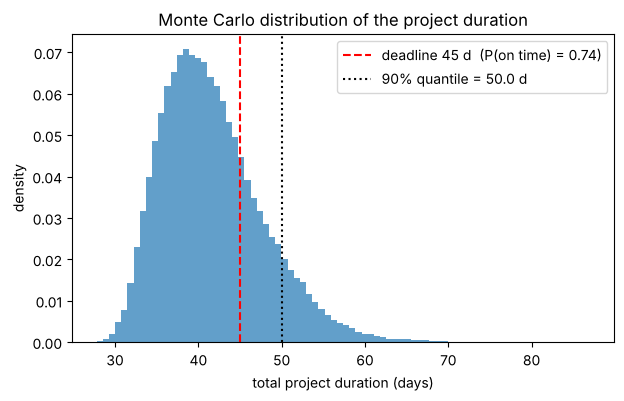


mean task durations, on-time vs late projects:
  design       on time  10.91   late  11.23
  procurement  on time   9.55   late  13.04
  build        on time  21.53   late  26.60
  testing      on time   5.74   late   9.20

P(late | procurement > 12 d) = 0.624   vs   P(late | procurement <= 12 d) = 0.124

P(on time) by sample size:
  n =     100: 0.7600  +/- 0.0427
  n =    1000: 0.7390  +/- 0.0139
  n =   10000: 0.7501  +/- 0.0043
  n =  100000: 0.7388  +/- 0.0014


In [21]:
rng = np.random.default_rng(2024)

def simulate_schedule(n_sims, rng):
    # Phase A tasks: design (uniform 8-14 days) and procurement (lognormal, median 10 days, 30% dispersion)
    design = rng.uniform(8, 14, size=n_sims)
    procurement = rng.lognormal(mean=np.log(10), sigma=0.3, size=n_sims)
    phase_a = np.maximum(design, procurement)                 # build can start only when both are done
    # Phase B: build (triangular 15-20-30 days)
    build = rng.triangular(15, 20, 30, size=n_sims)
    # dependency: a late procurement (> 12 days) means parts arrive in a rush and build takes 20% longer
    build = np.where(procurement > 12, 1.2 * build, build)
    # Phase C: testing; 1 in 4 projects needs a second test cycle (geometric number of cycles, p = 0.75)
    cycles = rng.geometric(0.75, size=n_sims)
    testing = rng.uniform(4, 6, size=(n_sims,)) * cycles
    return phase_a + build + testing, dict(design=design, procurement=procurement, build=build, testing=testing)

n_sims = 100_000
total, parts = simulate_schedule(n_sims, rng)
deadline = 45

p_on_time = (total <= deadline).mean()
se = np.sqrt(p_on_time * (1 - p_on_time) / n_sims)
q90 = np.quantile(total, 0.90)
naive_sum = 11 + 10 + (15 + 20 + 30) / 3 + 5 * (1 / 0.75)   # sum of all task means: treats parallel tasks as sequential
e_max = np.maximum(parts["design"], parts["procurement"]).mean()
print(f"mean duration        : {total.mean():6.2f} days")
print(f"naive sum of all task means: {naive_sum:.2f} days (too pessimistic: design and procurement run in parallel)")
print(f"E[max(design, procurement)] = {e_max:.2f}  >=  max of the means = 11.00  (the expected maximum is later than the later mean)")
print(f"median duration      : {np.median(total):6.2f} days")
print(f"P(finish within {deadline} d): {p_on_time:.4f} +/- {se:.4f}")
print(f"90% completion time  : {q90:6.2f} days   (promise this, not the mean)")
print(f"99% completion time  : {np.quantile(total, 0.99):6.2f} days")

plt.hist(total, bins=80, density=True, alpha=0.7)
plt.axvline(deadline, color="r", ls="--", label=f"deadline {deadline} d  (P(on time) = {p_on_time:.2f})")
plt.axvline(q90, color="k", ls=":", label=f"90% quantile = {q90:.1f} d")
plt.xlabel("total project duration (days)"); plt.ylabel("density")
plt.title("Monte Carlo distribution of the project duration"); plt.legend(); plt.show()

# sensitivity: which task drives lateness?  compare task means for late vs on-time projects
late = total > deadline
print("\nmean task durations, on-time vs late projects:")
for name, arr in parts.items():
    print(f"  {name:12s} on time {arr[~late].mean():6.2f}   late {arr[late].mean():6.2f}")
print(f"\nP(late | procurement > 12 d) = {late[parts['procurement'] > 12].mean():.3f}   vs   P(late | procurement <= 12 d) = {late[parts['procurement'] <= 12].mean():.3f}")

# convergence of the estimate with n
ns_ = [100, 1_000, 10_000, 100_000]
print("\nP(on time) by sample size:")
for m in ns_:
    t, _ = simulate_schedule(m, np.random.default_rng(1))
    p = (t <= deadline).mean()
    print(f"  n = {m:>7d}: {p:.4f}  +/- {np.sqrt(p*(1-p)/m):.4f}")

## Score

In [22]:
summary()


Score: 61/61 checks passed  🎉
